<a href="https://colab.research.google.com/github/alightnessaron-afk/COU07506-labs./blob/main/COU07506_Week03_240242425544.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

COU 07506 – Digital Signal Processing

Week 3: Lab 1B – Convolution, Correlation and Difference Equations

Name: Lightness Aron Japheti

Registration Number: 240242425544

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import time

plt.rcParams["figure.figsize"] = (9, 3.5)

task 3.1

In [2]:
def conv(x, h):

    N = len(x) + len(h) - 1

    y = np.zeros(N)

    for n in range(N):

        for k in range(len(x)):

            if 0 <= n - k < len(h):

                y[n] += x[k] * h[n - k]

    return y

In [3]:
x = [1, 2, 3, 1]

h = [1, 1, 1]

my_result = conv(x, h)

numpy_result = np.convolve(x, h)

print("My convolution:", my_result)

print("NumPy convolution:", numpy_result)

print("Results match:", np.allclose(my_result, numpy_result))

My convolution: [1. 3. 6. 6. 4. 1.]
NumPy convolution: [1 3 6 6 4 1]
Results match: True


In [4]:
x = [1, -1, 2]

h = [2, 1, 0, 1]

print("Convolution result:", conv(x, h))

Convolution result: [ 2. -1.  3.  3. -1.  2.]


In [5]:
x = np.random.rand(2000)

h = np.random.rand(2000)

start = time.perf_counter()

result1 = conv(x, h)

manual_time = time.perf_counter() - start

start = time.perf_counter()

result2 = np.convolve(x, h)

numpy_time = time.perf_counter() - start

print("Manual convolution time:", manual_time, "seconds")

print("NumPy convolution time:", numpy_time, "seconds")

Manual convolution time: 5.462701531999983 seconds
NumPy convolution time: 0.004320538999991186 seconds


task 3.2

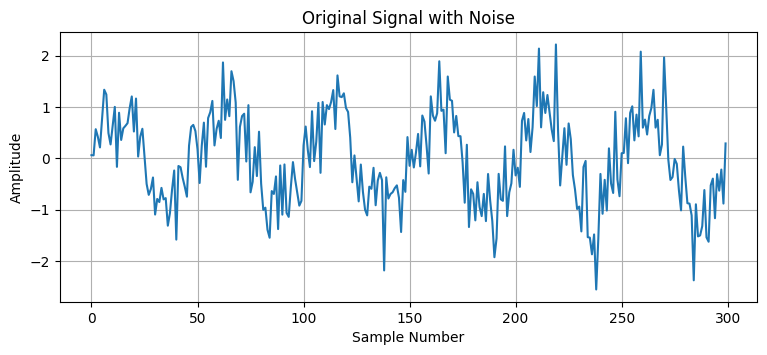

In [6]:
rng = np.random.default_rng(0)

n = np.arange(300)

x = np.sin(2 * np.pi * n / 50) + 0.5 * rng.standard_normal(300)

plt.plot(n, x)

plt.title("Original Signal with Noise")
plt.xlabel("Sample Number")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

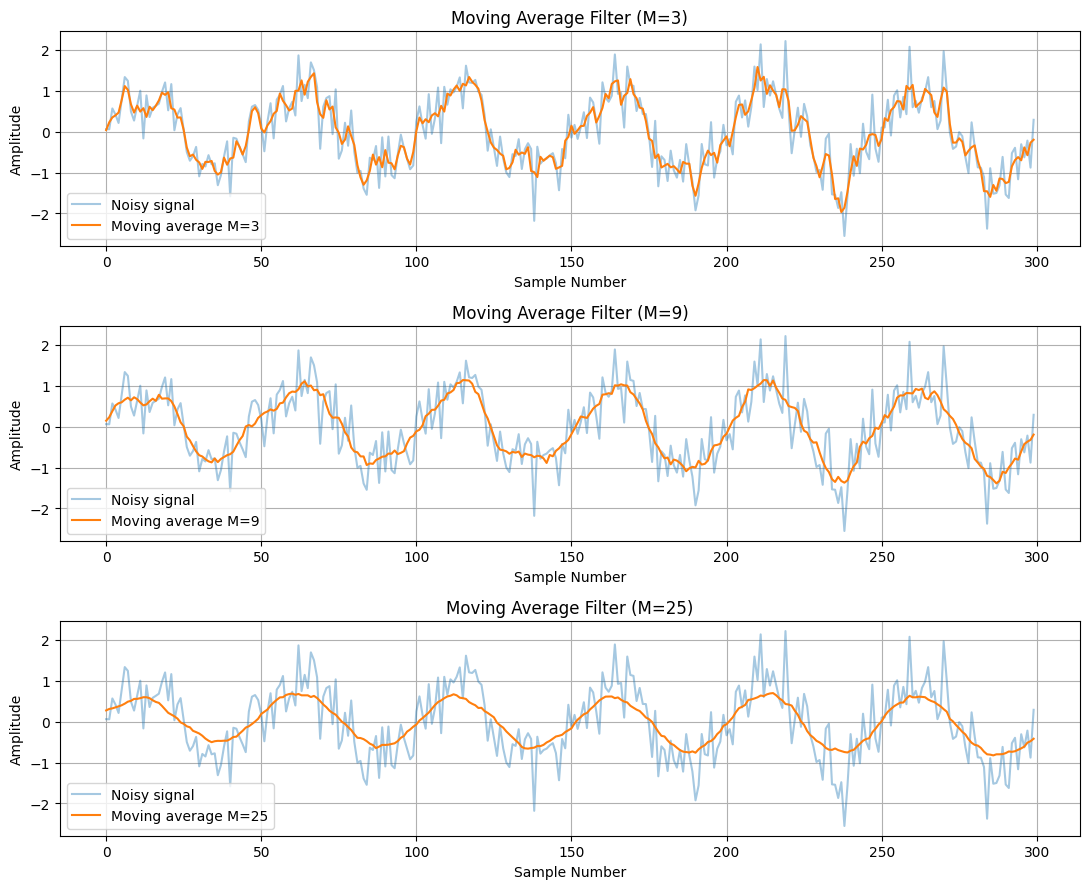

In [8]:
M_values = [3, 9, 25]

fig, axes = plt.subplots(3, 1, figsize=(11, 9))

for ax, M in zip(axes, M_values):

    h = np.ones(M) / M

    y = np.convolve(x, h, mode="same")

    ax.plot(n, x, alpha=0.4, label="Noisy signal")

    ax.plot(n, y, label=f"Moving average M={M}")

    ax.set_title(f"Moving Average Filter (M={M})")

    ax.set_xlabel("Sample Number")

    ax.set_ylabel("Amplitude")

    ax.legend()

    ax.grid(True)

plt.tight_layout()
plt.show()

Observation:

The moving average filter reduces noise in the original signal.
When the filter size increases, the output becomes smoother.
However, a larger filter size may distort the original signal
and remove some important details.

task 3.3

In [9]:
rng = np.random.default_rng(0)

x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)

a = 2.0
b = -3.0

systems = {
    "x^2": lambda x: x**2,

    "n*x(n)": lambda x: np.arange(len(x)) * x,

    "Moving Average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]
}

for name, T in systems.items():

    linear = np.allclose(
        T(a*x1 + b*x2),
        a*T(x1) + b*T(x2)
    )

    xd = np.concatenate([np.zeros(5), x1])[:50]

    yd = np.concatenate([np.zeros(5), T(x1)])[:50]

    tinv = np.allclose(T(xd), yd)

    print(name, "Linear =", linear, "Time-invariant =", tinv)

x^2 Linear = False Time-invariant = True
n*x(n) Linear = True Time-invariant = False
Moving Average Linear = True Time-invariant = True


In [10]:
rng = np.random.default_rng(1)

fs = 1000

x = rng.standard_normal(500)

true_delay = 37

y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500]

y = y + 0.5*rng.standard_normal(500)

print("Original signal length:", len(x))
print("Received signal length:", len(y))

Original signal length: 500
Received signal length: 500


Actual delay: 37 samples
Estimated delay: 37 samples


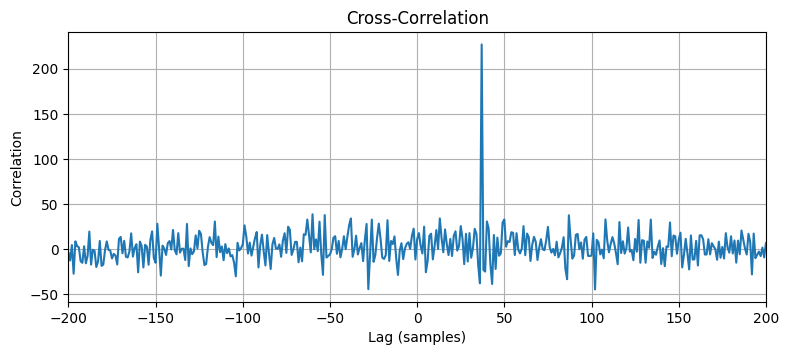

In [11]:
r = signal.correlate(y, x, mode="full")

lags = signal.correlation_lags(
    len(y), len(x), mode="full"
)

estimated_delay = lags[np.argmax(r)]

print("Actual delay:", true_delay, "samples")

print("Estimated delay:", estimated_delay, "samples")

plt.plot(lags, r)

plt.title("Cross-Correlation")
plt.xlabel("Lag (samples)")
plt.ylabel("Correlation")
plt.xlim(-200, 200)
plt.grid(True)
plt.show()

In [12]:
for noise_level in [0.5, 1, 2, 4]:

    noisy_y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500]

    noisy_y += noise_level * rng.standard_normal(500)

    r = signal.correlate(noisy_y, x, mode="full")

    lags = signal.correlation_lags(
        len(noisy_y), len(x), mode="full"
    )

    delay = lags[np.argmax(r)]

    print("Noise:", noise_level,
          "| Estimated delay:", delay, "samples")

Noise: 0.5 | Estimated delay: 37 samples
Noise: 1 | Estimated delay: 37 samples
Noise: 2 | Estimated delay: 37 samples
Noise: 4 | Estimated delay: 37 samples



v=343 m/s


t=37/1000=0.037s

d=vt

d=343(0.037)=12.691m

The estimated distance is approximately 12.69 metres, assuming the sound travels one way between the transmitter and receiver. For an echo measurement involving a round trip, the distance would be half this value.



task 3.5

For 𝑦(𝑛) − 3/
4y(𝑛 −1)+1
8
𝑦(𝑛 −2) = 𝑥(𝑛)+𝑥(𝑛−1):

In [13]:
N = 10

x = np.zeros(N)

x[0] = 1

y = np.zeros(N)

for n in range(N):

    x_previous = x[n-1] if n >= 1 else 0

    y_previous = y[n-1] if n >= 1 else 0

    y_previous2 = y[n-2] if n >= 2 else 0

    y[n] = (
        x[n] + x_previous
        + 0.75*y_previous
        - 0.125*y_previous2
    )

print("Impulse response:")
print(y)

Impulse response:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


In [14]:
impulse = np.zeros(10)

impulse[0] = 1

h = signal.lfilter(
    [1, 1],
    [1, -0.75, 0.125],
    impulse
)

print("Direct iteration:", y)

print("Using lfilter:", h)

print("Results match:", np.allclose(y, h))

Direct iteration: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Using lfilter: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Results match: True


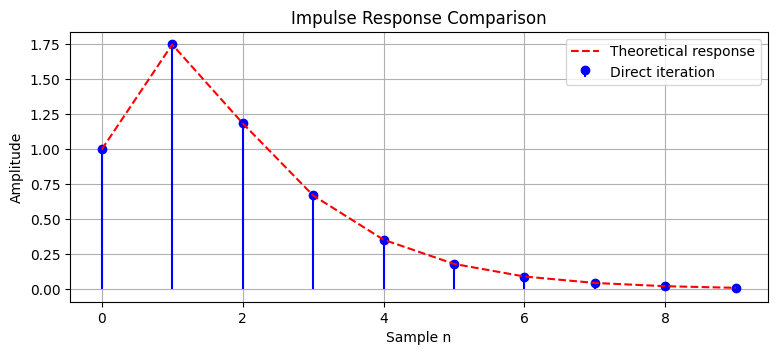

Responses match: True


In [15]:
n = np.arange(10)

h_theoretical = 6*(0.5**n) - 5*(0.25**n)

plt.stem(n, y, linefmt="b-", markerfmt="bo",
         basefmt=" ", label="Direct iteration")

plt.plot(n, h_theoretical, "r--",
         label="Theoretical response")

plt.title("Impulse Response Comparison")
plt.xlabel("Sample n")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

print("Responses match:",
      np.allclose(y, h_theoretical))

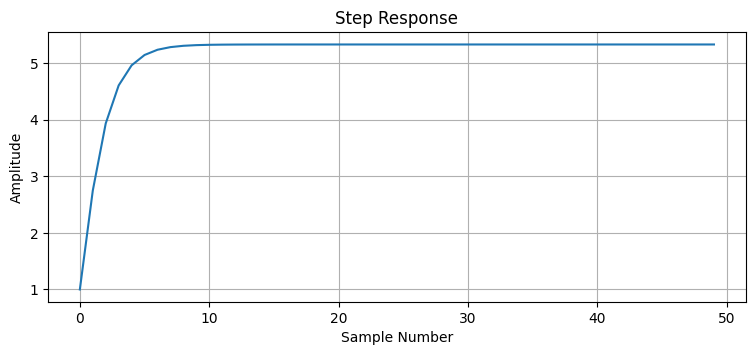

Theoretical final value: 5.333333333333333
Measured final value: 5.333333333333323


In [16]:
step_input = np.ones(50)

step_output = signal.lfilter(
    [1, 1],
    [1, -0.75, 0.125],
    step_input
)

plt.plot(step_output)

plt.title("Step Response")
plt.xlabel("Sample Number")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

final_value = (1 + 1) / (1 - 0.75 + 0.125)

print("Theoretical final value:", final_value)

print("Measured final value:", step_output[-1])

Week 03: Analysis Questions

1. Why is np.convolve faster than a manually written convolution function?



np.convolve() is faster because it uses optimized numerical operations implemented in compiled code, while a manually written function uses Python loops. For input lengths L and M, direct convolution requires approximately L × M multiplications.

2. Which systems are LTI?


- \(x^2\): Nonlinear and time-invariant.
- \(nx(n)\): Linear but time-varying.
- Moving average: Linear and time-invariant.
Therefore, only the moving average system is LTI.

3. Give two engineering applications of cross-correlation in Tanzania.


1. Water pipe leak detection: Cross-correlation can compare signals from sensors to estimate the location of a water leak.
2. Radar systems: Cross-correlation can help detect and estimate the delay of reflected signals.
4. Is the system in Task 3.5 FIR or IIR? Is it stable?



The system is an IIR filter because it uses previous output values in its difference equation. It is stable because its poles are at 0.5 and 0.25, which are inside the unit circle. Therefore, its impulse response decays with time.